Q5. Image Binary Classification (30 pts)
Complete this question in two separate notebooks (see Project Requirements): LastName_FirstName_HW3_Q5a.ipynb for Tasks 5.1 and 5.2, and LastName_FirstName_HW3_Q5b.ipynb for Task 5.3. Copy the relevant task descriptions into each notebook as markdown.

Datasets (posted on Brightspace with this notebook):

training set: train_catvnoncat.h5 (209 images; keys train_set_x, train_set_y, list_classes)
test set: test_catvnoncat.h5 (50 images; keys test_set_x, test_set_y, list_classes)
Place both .h5 files in the same folder as your Q5 notebooks. The loading code opens the files by name only, so it will fail with FileNotFoundError if they are stored elsewhere. Do not hard-code a full path from your own computer, since the grader must be able to run your notebook unchanged.

Each image is a
 RGB image, and each label is
 (cat) or
 (non-cat). Read the files with h5py. Flatten each image into a vector of
 pixel values and scale the pixel values to
 by dividing by 255.

All indices you report must be 0-based, following Python convention


5.1 Re-implement the classifier (10 pts) (notebook Q5a). Re-implement, from scratch, the logistic regression image classifier covered in class: parameter initialization, forward pass (sigmoid), cost, gradients, the gradient descent update loop, and a prediction function. You may consult the class code on Brightspace if you get stuck, but write the code yourself. Print the learning rate and number of iterations you used, plot the cost versus iteration, and print the training and test accuracies (in %, 2 decimals).

This code loads the cat/non-cat images, converts every $64\times64\times3$
RGB image into a normalized vector of $12{,}288$ pixel features, and
stores the training data as $X \in \mathbb{R}^{12288 \times 209}$.

The logistic-regression model calculates
$\hat{Y}=\sigma(\mathbf{w}^T X+b)$, evaluates binary cross-entropy
cost $J$, computes the gradients $d\mathbf{w}$ and $db$, and uses
gradient descent to update $\mathbf{w}$ and $b$ during training.

In [38]:
import numpy as np
import h5py
import matplotlib.pyplot as plt

#imports images
with h5py.File("train_catvnoncat.h5", "r") as train_file:
    train_x_orig = np.array(train_file["train_set_x"][:])
    train_y_orig = np.array(train_file["train_set_y"][:])

with h5py.File("test_catvnoncat.h5", "r") as test_file:
    test_x_orig = np.array(test_file["test_set_x"][:])
    test_y_orig = np.array(test_file["test_set_y"][:])


#print(train_x_orig.shape) to see if image are the roght shape
#print(train_y_orig.shape)
#print(test_x_orig.shape)
#print(test_y_orig.shape)

#Flatten and scale them for your classifier

# Each image becomes 12,288 pixel features: 64 * 64 * 3
# .T transposes the result so columns are images and rows are features.
# Scale pixel values from the range 0–255 to the range 0–1.
# Scaling helps gradient descent train more reliably.

train_x = train_x_orig.reshape(train_x_orig.shape[0], -1).T / 255.0

# Flatten each test image in the same way.
test_x = test_x_orig.reshape(test_x_orig.shape[0], -1).T / 255.0

#Reshape labels into row vectors.
# This gives train_y shape (1, 209) and test_y shape (1, 50).
train_y = train_y_orig.reshape(1, -1)
test_y = test_y_orig.reshape(1, -1)

 # print(train_x.shape)  # expected: (12288, 209)
 #print(test_x.shape)   # expected: (12288, 50)

#classifier functions

#The sigmoid function allows us to take an input and have it mapped between 0 and 1
#This is useful because we desire to output a probability
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def initialize_parameters(dim):
    # Create a column vector of zeros:
    # one weight for each pixel feature
    w = np.zeros((dim,1))
    # Start the bias at zero
    b = 0.0
    # Return the starting parameters
    return w, b

#function for forward calculation of logistic regression
def propagate(w, b, X, Y):
    # Number of images/training examples
    m = X.shape[1]

    # Forward pass:
    # Calculate z = wᵀX + b, then turn scores into probabilities from 0 to 1
    A = sigmoid(np.dot(w.T, X) + b)

    # Avoid log(0), which would cause an error in the cost calculation
    A_safe = np.clip(A, 1e-12, 1 - 1e-12)
    # Calculate average binary cross-entropy cost i.e J
    cost = -np.sum(
        Y * np.log(A_safe) + (1 - Y) * np.log(1 - A_safe)
    ) / m

    # Gradients

    # Calculate the gradient of the cost with respect to w
    # This tells us how to adjust each weight
    dw = np.dot(X, (A - Y).T) / m

    # Store both gradients in a dictionary
    db = np.sum(A - Y) / m
    # Return the gradients and one numerical cost value
    grads = {"dw": dw, "db": db}

    return grads, float(cost)
# optimize repeatedly calls propagate, then uses the gradients to update w and b.
def optimize(w, b, X, Y, num_iterations, learning_rate, print_cost=False):
    # Store the cost from every iteration for the required cost plot
    costs = []

    # Repeat gradient descent for the chosen number of iterations
    for i in range(num_iterations):

        # Calculate the current cost and gradients
        grads, cost = propagate(w, b, X, Y)

        # Retrieve the gradients from the dictionary
        dw = grads["dw"]
        db = grads["db"]

        # Update the weights and bias using gradient descent
        # Move in the direction that reduces the cost
        w = w - learning_rate * dw
        b = b - learning_rate * db

        # Save this iteration's cost for plotting later
        costs.append(cost)

        # Optionally print the cost every 100 iterations
        if print_cost and i % 100 == 0:
            print(f"Cost at iteration {i}: {cost:.6f}")

    # Store the final learned parameters
    params = {"w": w, "b": b}

    # Return the final parameters, final gradients, and cost history
    return params, grads, costs

def predict(w, b, X):
    # Calculate the probability that each image is a cat
    # A has one probability for each image
    A = sigmoid(np.dot(w.T, X) + b)

    # Convert probabilities into class predictions:
    # probability > 0.5 becomes 1 (cat)
    # probability <= 0.5 becomes 0 (non-cat)
    Y_prediction = (A > 0.5).astype(int)

    # Return the predicted labels
    return Y_prediction
# Convert numeric labels into readable text.
def label_name(label):
    return "cat" if label == 1 else "non-cat"


This code initializes $\mathbf{w}$ and $b$ at zero, then trains the
logistic-regression model for $2000$ iterations using learning rate
$\alpha=0.005$ to minimize the binary cross-entropy cost.

After training, it uses the learned parameters to predict labels for
both data sets, reports their accuracies, and plots the cost $J$ versus
iteration to show how training progresses.

In [39]:
# Choose starting hyperparameters.
# adjust learning rate and num iterations .
learning_rate = 0.005
num_iterations = 2000

# Create the initial zero weights and bias.
w, b = initialize_parameters(train_x.shape[0])

# Train the model using the training images and labels.
params, grads, costs = optimize(
    w,
    b,
    train_x,
    train_y,
    num_iterations,
    learning_rate,
    print_cost=True
)

# Get the learned weights and bias after training.
w = params["w"]
b = params["b"]

# Make predictions for the training and test image sets.
train_predictions = predict(w, b, train_x)
test_predictions = predict(w, b, test_x)


# Calculate accuracy as a percentage.
train_accuracy = np.mean(train_predictions == train_y) * 100
test_accuracy = np.mean(test_predictions == test_y) * 100

# Print the required results.
print(f"Learning rate: {learning_rate}")
print(f"Number of iterations: {num_iterations}")
print(f"Training accuracy: {train_accuracy:.2f}%")
print(f"Test accuracy: {test_accuracy:.2f}%")

Cost at iteration 0: 0.693147
Cost at iteration 100: 0.584508
Cost at iteration 200: 0.466949
Cost at iteration 300: 0.376007
Cost at iteration 400: 0.331463
Cost at iteration 500: 0.303273
Cost at iteration 600: 0.279880
Cost at iteration 700: 0.260042
Cost at iteration 800: 0.242941
Cost at iteration 900: 0.228004
Cost at iteration 1000: 0.214820
Cost at iteration 1100: 0.203078
Cost at iteration 1200: 0.192544
Cost at iteration 1300: 0.183033
Cost at iteration 1400: 0.174399
Cost at iteration 1500: 0.166521
Cost at iteration 1600: 0.159305
Cost at iteration 1700: 0.152667
Cost at iteration 1800: 0.146542
Cost at iteration 1900: 0.140872
Learning rate: 0.005
Number of iterations: 2000
Training accuracy: 99.04%
Test accuracy: 70.00%


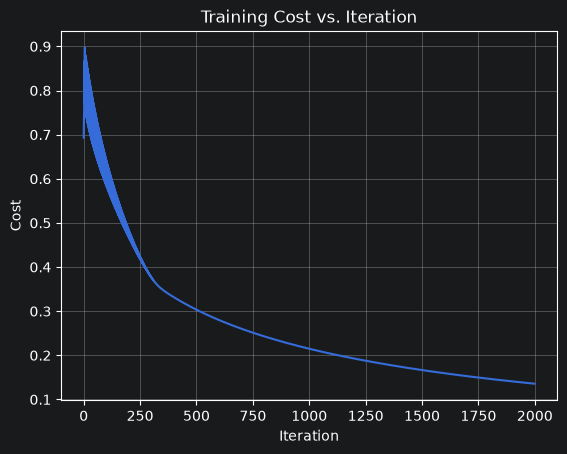

In [40]:
plt.plot(costs)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.title("Training Cost vs. Iteration")
plt.grid()
plt.show()

5.2 Failure analysis (8 pts) (notebook Q5a).

(4 pts) Print the indices of all images in the test set that the model misclassifies, and the total count.
(4 pts) Display at least 4 of these misclassified images in a grid. Title each image with its index, true label, and predicted label (for example, idx 5: true=cat, pred=non-cat).

This code compares the predicted test labels $\hat{Y}$ with the true
labels $Y$ to find all zero-based indexes where
$\hat{y}_i \ne y_i$.

It prints the incorrect indexes and displays the first four
misclassified original RGB images, labeling each with its index, true
class, and predicted class.

Misclassified test set indices: [ 5  6 10 11 13 18 19 28 29 30 33 34 41 44 46]
Total misclassified images: 15


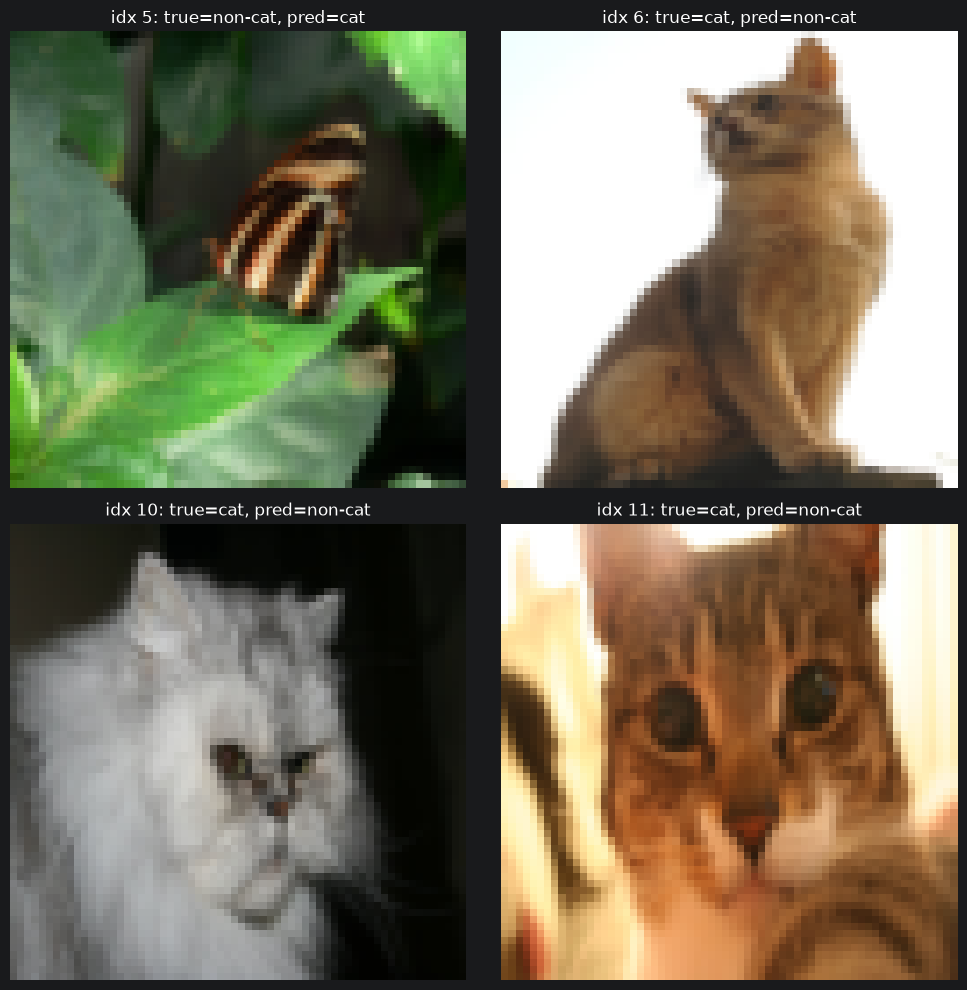

In [41]:
# Compared predicted test labels with the true test labels.
# .ravel() changes both arrays into one dimensional arrays of length 50.
incorrect = test_predictions.ravel() != test_y.ravel()

# Gets the zero based test set indexes where the prediction was incorrect.
misclassified_indices = np.where(incorrect)[0]

# Print every misclassified test image index and the total number.
print("Misclassified test set indices:", misclassified_indices)
print("Total misclassified images:", len(misclassified_indices))

# Chooses up to the first four incorrectly classified test images.
images_to_show = misclassified_indices[:4]

# Handes the unusual case where every test image was classified correctly.
if len(images_to_show) == 0:
    print("There are no misclassified test images to display.")

else:
# Create a 2 by 2 grid for four images.
    fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# Flattens the 2 by 2 grid into one list of four axes.
    axes = axes.ravel()

# Display each misclassified image.
for ax, idx in zip(axes, images_to_show):

# Uses test_x_orig because it still has the original image shape:
# (64, 64, 3), rather than the flattened 12,288 4pixel vector.
    ax.imshow(test_x_orig[idx])

    true_label = label_name(test_y[0, idx])
    predicted_label = label_name(test_predictions[0, idx])

    ax.set_title(
    f"idx {idx}: true={true_label}, pred={predicted_label}"
)

# Add the required title with test set index, true label, and prediction.
    ax.set_title(
    f"idx {idx}: true={true_label}, pred={predicted_label}"
)

# Hide x- and y-axis numbers because they are not useful for an image.
    ax.axis("off")

# Hide unused spaces if there are fewer than four incorrect images.
for ax in axes[len(images_to_show):]:
    ax.axis("off")

# Prevent titles and images from overlapping.
plt.tight_layout()
plt.show()